# Real-Time Multilingual Meeting Assistant — Telugu / Tamil (and other Indic languages)
**Pipeline:** audio → Silero VAD → IndicWhisper (per-language ASR) → IndicTrans2 (Indic → English) → captions

Run the cells **top to bottom, once**. Before you start:
1. Turn on **GPU (T4)** and **Internet**.
2. Add your Hugging Face token as a Kaggle secret named `HF_TOKEN` (and make sure your account has access to `ai4bharat/indictrans2-indic-en-dist-200M`).
3. Attach one Kaggle dataset per language that holds that language's IndicWhisper checkpoint (from the Vistaar repo), then edit `LANG_INFO` / `RUN_LANGS` in section 3.

**What gets measured (per language):**

| Block | Metrics |
|---|---|
| ASR accuracy | WER, CER, substitution / deletion / insertion rates, median and 90th-percentile WER, exact-match %, WER per data source |
| ASR speed & cost | latency mean / p50 / p95, real-time factor (RTF), peak GPU memory, parameter count, model load time |
| Reliability | repetition / hallucination rate |
| Translation (text → English) | BLEU, chrF, chrF++ on IN22-Gen, sentence latency |
| Error propagation | chrF / BLEU of translate(ASR output) vs translate(gold transcript) |
| Streaming (simulated meeting) | caption latency (mean / p50 / p95 / max), % captions within 3 s / 5 s, time-to-first-caption, stream RTF, stream WER, segments per utterance, queue wait |
| Ablations | VAD silence threshold (250 / 500 / 800 / 1200 ms) vs fixed 3 s / 5 s chunking |
| Robustness | WER at clean, 20, 10, 5, 0 dB SNR (added white noise) |

## 1. Install packages

In [1]:
!pip install -q "transformers<5" jiwer sacrebleu soundfile librosa silero-vad datasets matplotlib
!pip install -q git+https://github.com/VarunGumma/IndicTransToolkit.git

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


## 2. Patch IndicTransToolkit (import path fix for newer transformers)

In [2]:
import importlib.util, pathlib

pkg_dir = pathlib.Path(importlib.util.find_spec("IndicTransToolkit").submodule_search_locations[0])
f = pkg_dir / "collator.py"
txt = f.read_text()
txt = txt.replace(
    "from transformers.tokenization_utils import PreTrainedTokenizerBase",
    "from transformers.tokenization_utils_base import PreTrainedTokenizerBase",
)
f.write_text(txt)
print("patched:", f)

patched: /usr/local/lib/python3.13/dist-packages/IndicTransToolkit/collator.py


## 3. Configuration  — EDIT `LANG_INFO` and `RUN_LANGS`

In [3]:
import os, re, gc, time, json, unicodedata, warnings
import numpy as np
import pandas as pd
import torch

warnings.filterwarnings("ignore")
SR = 16000
SEED = 42
OUT_DIR = "/kaggle/working/results_multilingual"
os.makedirs(OUT_DIR, exist_ok=True)

# ---------------------------------------------------------------------------------
# model_root = folder of the attached Kaggle dataset that contains that language's
# IndicWhisper checkpoint. The code searches inside it for the folder with config.json
# (and prefers a folder whose name contains "medium" if several exist).
# tag = IndicTrans2 language code.
# ---------------------------------------------------------------------------------
LANG_INFO = {
    "hi": dict(name="Hindi",     tag="hin_Deva", model_root="/kaggle/input/datasets/alwalmedhana/hindi-models"),
    "te": dict(name="Telugu",    tag="tel_Telu", model_root="/kaggle/input/datasets/alwalmedhana/telugu-models"),   # <-- edit
    "ta": dict(name="Tamil",     tag="tam_Taml", model_root="/kaggle/input/datasets/alwalmedhana/tamil-models"),    # <-- edit
    "bn": dict(name="Bengali",   tag="ben_Beng", model_root=None),
    "kn": dict(name="Kannada",   tag="kan_Knda", model_root=None),
    "ml": dict(name="Malayalam", tag="mal_Mlym", model_root=None),
    "mr": dict(name="Marathi",   tag="mar_Deva", model_root=None),
    "gu": dict(name="Gujarati",  tag="guj_Gujr", model_root=None),
    "pa": dict(name="Punjabi",   tag="pan_Guru", model_root=None),
    "or": dict(name="Odia",      tag="ory_Orya", model_root=None),
}
RUN_LANGS = ["te", "ta"]          # start with ONE language to test, then add the other

# ---- evaluation sizes (lower these first if you are short on time) ----
N_ASR = 100            # ASR test clips per language
N_MT = 200             # sentences for text-to-text translation scoring
N_CASCADE = 50         # clips used for ASR->MT error-propagation measurement
N_STREAM_UTT = 12      # utterances stitched into the simulated meeting
N_NOISE = 40           # clips used for the noise-robustness test
NOISE_SNRS = [20, 10, 5, 0]

# ---- streaming settings ----
GAP_S = 1.0            # silence between utterances in the simulated meeting
MAX_SEG_S = 8          # VAD forced cut for non-stop speech
MAIN_SILENCE_MS = 500  # the VAD setting reported as the "main" streaming result
VAD_SILENCE_MS = [250, 500, 800, 1200]
FIXED_CHUNKS_S = [3, 5]
MT_BS = 8
MAX_AUDIO_S = 30

device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float16 if device == "cuda" else torch.float32
print("device:", device, "|", torch.cuda.get_device_name(0) if device == "cuda" else "CPU only")
USE_FINETUNED = False            # set True for the second run
FT_ROOT = "/kaggle/input/<your-lora-output-dataset>/finetuned"
if USE_FINETUNED:
    for l in ("te", "ta"):
        LANG_INFO[l]["model_root"] = f"{FT_ROOT}/{l}/merged"
    OUT_DIR = "/kaggle/working/results_finetuned"
    os.makedirs(OUT_DIR, exist_ok=True)

device: cuda | Tesla T4


## 4. Hugging Face login (needed for IndicTrans2)

In [4]:
from kaggle_secrets import UserSecretsClient
from huggingface_hub import login, whoami, hf_hub_download

login(token=UserSecretsClient().get_secret("HF_TOKEN"))
print("logged in as:", whoami()["name"])
hf_hub_download("ai4bharat/indictrans2-indic-en-dist-200M", "config.json")
print("IndicTrans2 access OK")

logged in as: Medhana


config.json: 0.00B [00:00, ?B/s]

IndicTrans2 access OK


## 5. Helper functions (text normalisation, audio, model discovery)

In [5]:
def normalize_text(t):
    # language-agnostic: NFC, drop zero-width chars, replace punctuation/symbols by space
    if t is None:
        return ""
    t = unicodedata.normalize("NFC", str(t))
    t = t.replace("\u200c", "").replace("\u200d", "")
    t = "".join(" " if unicodedata.category(ch)[0] in ("P", "S") else ch for ch in t)
    return re.sub(r"\s+", " ", t).strip().lower()


def find_model_dir(root, prefer=("medium",)):
    if not root or not os.path.isdir(root):
        raise FileNotFoundError(
            f"model_root not found: {root!r}. Attach the dataset and fix the path in LANG_INFO "
            f"(use !find /kaggle/input -name config.json to locate it)."
        )
    cands = []
    for dp, dn, fn in os.walk(root):
        has_cfg = "config.json" in fn
        has_w = any(f.startswith(("pytorch_model", "model")) and f.endswith((".bin", ".safetensors")) for f in fn)
        if has_cfg and has_w:
            cands.append(dp)
    if not cands:
        raise FileNotFoundError(f"No folder with config.json + weights under {root}")
    cands.sort(key=lambda p: (0 if any(k in os.path.basename(p).lower() for k in prefer) else 1, p))
    if len(cands) > 1:
        print("  checkpoints found:", [os.path.basename(c) for c in cands], "-> using", os.path.basename(cands[0]))
    return cands[0]


def get_audio(a):
    try:
        arr = a["array"]
        sr = a["sampling_rate"]
    except Exception:
        s = a.get_all_samples()
        arr, sr = s.data.numpy(), s.sample_rate
    arr = np.asarray(arr, dtype=np.float32)
    if arr.ndim > 1:
        arr = arr.mean(axis=0) if arr.shape[0] < arr.shape[-1] else arr.mean(axis=-1)
    if sr != SR:
        import librosa
        arr = librosa.resample(arr, orig_sr=sr, target_sr=SR)
    return arr


def has_repetition(text, k=3):
    # flags Whisper-style hallucination loops: same word k times in a row, or a 3-gram 3+ times
    w = text.split()
    run = 1
    for a, b in zip(w, w[1:]):
        run = run + 1 if a == b else 1
        if run >= k:
            return True
    grams = {}
    for i in range(len(w) - 2):
        g = tuple(w[i:i + 3])
        grams[g] = grams.get(g, 0) + 1
        if grams[g] >= 3:
            return True
    return False


def pct(x, q):
    return float(np.percentile(np.asarray(x, dtype=float), q))

## 6. Load IndicTrans2 once (shared by all languages) and the VAD

In [6]:
from transformers import AutoModelForSeq2SeqLM, AutoTokenizer
from IndicTransToolkit.processor import IndicProcessor

MT_CKPT = "ai4bharat/indictrans2-indic-en-dist-200M"
mt_tok = AutoTokenizer.from_pretrained(MT_CKPT, trust_remote_code=True)
t0 = time.time()
mt_model = AutoModelForSeq2SeqLM.from_pretrained(MT_CKPT, trust_remote_code=True, dtype=dtype).to(device)
mt_model.eval()
MT_LOAD_S = time.time() - t0
MT_PARAMS_M = sum(p.numel() for p in mt_model.parameters()) / 1e6
ip = IndicProcessor(inference=True)
print(f"IndicTrans2 loaded in {MT_LOAD_S:.1f}s, {MT_PARAMS_M:.0f}M params")


def _translate(sentences, tag, use_cache):
    batch = ip.preprocess_batch(sentences, src_lang=tag, tgt_lang="eng_Latn")
    inputs = mt_tok(batch, truncation=True, padding="longest", return_tensors="pt",
                    return_attention_mask=True).to(device)
    with torch.no_grad():
        out = mt_model.generate(**inputs, use_cache=use_cache, min_length=0, max_length=256,
                                num_beams=5, num_return_sequences=1)
    dec = mt_tok.batch_decode(out, skip_special_tokens=True, clean_up_tokenization_spaces=True)
    return ip.postprocess_batch(dec, lang="eng_Latn")


# IndicTrans2's custom code breaks with the KV-cache on some transformers versions.
# Probe once: use the cache (faster) if it works, otherwise turn it off.
MT_USE_CACHE = False
try:
    _translate(["आज हम बैठक शुरू करेंगे"], "hin_Deva", True)
    MT_USE_CACHE = True
except Exception as e:
    print("KV-cache not usable with this transformers version -> use_cache=False (slower). Reason:", type(e).__name__)
print("MT_USE_CACHE =", MT_USE_CACHE)


def translate_batch(texts, tag, bs=MT_BS):
    outs = [""] * len(texts)
    idx = sorted([i for i, t in enumerate(texts) if t and t.strip()], key=lambda i: len(texts[i]))
    for k in range(0, len(idx), bs):
        ci = idx[k:k + bs]
        res = _translate([texts[i] for i in ci], tag, MT_USE_CACHE)
        for i, r in zip(ci, res):
            outs[i] = r
    return outs


from silero_vad import load_silero_vad, get_speech_timestamps
VAD = load_silero_vad()
print("Silero VAD ready")

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenization_indictrans.py: 0.00B [00:00, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/ai4bharat/indictrans2-indic-en-dist-200M:
- tokenization_indictrans.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


dict.SRC.json: 0.00B [00:00, ?B/s]

dict.TGT.json: 0.00B [00:00, ?B/s]

...

modeling_indictrans.py: 0.00B [00:00, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/ai4bharat/indictrans2-indic-en-dist-200M:
- modeling_indictrans.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


model.safetensors:   0%|          | 0.00/913M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/163 [00:00<?, ?B/s]

IndicTrans2 loaded in 11.8s, 212M params
KV-cache not usable with this transformers version -> use_cache=False (slower). Reason: AttributeError
MT_USE_CACHE = False
Silero VAD ready


## 7. Data loaders (ASR test clips and translation test sentences)

In [7]:
ASR_EVAL_REPO = "ekacare/vistaar_small_asr_eval"
FLEURS_CFG = {"hi": "hi_in", "te": "te_in", "ta": "ta_in", "bn": "bn_in", "kn": "kn_in", "ml": "ml_in",
              "mr": "mr_in", "gu": "gu_in", "pa": "pa_in", "or": "or_in"}


def load_asr_samples(lang, n=N_ASR):
    from datasets import load_dataset, get_dataset_config_names
    ds, used = None, None
    try:
        cfgs = get_dataset_config_names(ASR_EVAL_REPO)
        print("  vistaar_small_asr_eval configs:", cfgs)
        if lang in cfgs:
            ds = load_dataset(ASR_EVAL_REPO, lang, split="test")
            used = f"{ASR_EVAL_REPO}:{lang}"
    except Exception as e:
        print("  vistaar_small_asr_eval unavailable:", repr(e)[:200])
    if ds is None:
        try:
            ds = load_dataset("google/fleurs", FLEURS_CFG[lang], split="test")
            used = f"google/fleurs:{FLEURS_CFG[lang]}"
            print("  falling back to", used)
        except Exception as e:
            raise RuntimeError(
                f"No ASR test set could be loaded for '{lang}'. Last error: {repr(e)[:200]}. "
                f"Upload your own recordings + transcripts and build `samples` manually "
                f"(list of dicts with audio/text/duration/source)."
            )
    cols = ds.column_names
    text_col = next(c for c in ("text", "transcription", "sentence", "raw_transcription") if c in cols)
    if "duration" in cols:
        ds = ds.filter(lambda d: 0.5 <= d <= MAX_AUDIO_S, input_columns=["duration"])
    ds = ds.shuffle(seed=SEED)
    samples = []
    for row in ds:
        if not normalize_text(row[text_col]):
            continue
        audio = get_audio(row["audio"])
        dur = len(audio) / SR
        if dur < 0.5 or dur > MAX_AUDIO_S:
            continue
        samples.append(dict(audio=audio, text=row[text_col], duration=dur, source=row.get("source", used)))
        if len(samples) >= n:
            break
    print(f"  loaded {len(samples)} ASR clips from {used} ({sum(s['duration'] for s in samples):.0f}s)")
    return samples


def load_mt_pairs(tag, n=N_MT):
    try:
        from datasets import load_dataset
        dd = load_dataset("ai4bharat/IN22-Gen")
        d = dd[list(dd.keys())[0]]
        cols = d.column_names
        if tag in cols and "eng_Latn" in cols:
            src, ref = d[tag], d["eng_Latn"]
        else:
            print("  IN22-Gen columns not as expected, MT scoring skipped. Columns:", cols[:30])
            return None
        pairs = [(s, r) for s, r in zip(src, ref) if s and r and str(s).strip() and str(r).strip()]
        order = np.random.RandomState(SEED).permutation(len(pairs))[:n]
        pairs = [pairs[i] for i in order]
        return [p[0] for p in pairs], [p[1] for p in pairs]
    except Exception as e:
        print("  IN22-Gen unavailable, MT scoring skipped:", repr(e)[:200])
        return None

## 8. ASR loading and evaluation (accuracy, speed, memory, hallucination)

In [8]:
from transformers import pipeline


def load_asr(lang):
    path = find_model_dir(LANG_INFO[lang]["model_root"])
    t0 = time.time()
    asr = pipeline("automatic-speech-recognition", model=path,
                   device=0 if device == "cuda" else -1, dtype=dtype)
    load_s = time.time() - t0
    n_params = sum(p.numel() for p in asr.model.parameters())
    return asr, path, load_s, n_params


def make_asr_fn(asr, lang):
    kw = {"task": "transcribe"}
    if lang != "or":                      # Odia is not a Whisper-supported language code
        kw["language"] = lang

    def fn(x):
        return asr({"raw": np.asarray(x, dtype=np.float32), "sampling_rate": SR},
                   generate_kwargs=kw)["text"].strip()
    return fn


def eval_asr(asr_fn, samples):
    import jiwer
    asr_fn(samples[0]["audio"])                      # warm-up (not timed)
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()
    rows = []
    for i, s in enumerate(samples):
        t0 = time.perf_counter()
        hyp = asr_fn(s["audio"])
        dt = time.perf_counter() - t0
        ref_n, hyp_n = normalize_text(s["text"]), normalize_text(hyp)
        rows.append(dict(
            id=i, source=s.get("source") or "unknown", duration_s=s["duration"], ref=s["text"], hyp=hyp,
            ref_n=ref_n, hyp_n=hyp_n,
            wer=jiwer.wer(ref_n, hyp_n) if hyp_n else 1.0,
            cer=jiwer.cer(ref_n, hyp_n) if hyp_n else 1.0,
            latency_s=dt, rtf=dt / s["duration"], repetition=has_repetition(hyp_n)))
        if (i + 1) % 20 == 0:
            print(f"  ASR {i + 1}/{len(samples)}")
    df = pd.DataFrame(rows)
    refs, hyps = df.ref_n.tolist(), df.hyp_n.tolist()
    pw = jiwer.process_words(refs, hyps)
    pc = jiwer.process_characters(refs, hyps)
    n_ref = pw.hits + pw.substitutions + pw.deletions
    m = {
        "ASR_WER_%": pw.wer * 100,
        "ASR_CER_%": pc.cer * 100,
        "ASR_substitution_%": 100 * pw.substitutions / n_ref,
        "ASR_deletion_%": 100 * pw.deletions / n_ref,
        "ASR_insertion_%": 100 * pw.insertions / n_ref,
        "ASR_WER_median_%": float(df.wer.median() * 100),
        "ASR_WER_p90_%": float(df.wer.quantile(0.9) * 100),
        "ASR_exact_match_%": float((df.wer == 0).mean() * 100),
        "ASR_latency_mean_s": float(df.latency_s.mean()),
        "ASR_latency_p50_s": pct(df.latency_s, 50),
        "ASR_latency_p95_s": pct(df.latency_s, 95),
        "ASR_RTF_overall": float(df.latency_s.sum() / df.duration_s.sum()),
        "ASR_RTF_p95": pct(df.rtf, 95),
        "ASR_repetition_%": float(df.repetition.mean() * 100),
        "GPU_peak_mem_GB": (torch.cuda.max_memory_allocated() / 1024 ** 3) if torch.cuda.is_available() else 0.0,
    }
    src_rows = []
    for src, g in df.groupby("source"):
        src_rows.append(dict(source=src, n=len(g), audio_s=g.duration_s.sum(),
                             WER=jiwer.wer(g.ref_n.tolist(), g.hyp_n.tolist()) * 100,
                             CER=jiwer.cer(g.ref_n.tolist(), g.hyp_n.tolist()) * 100))
    return m, df, pd.DataFrame(src_rows)

## 9. Translation evaluation (text → English) and ASR→MT error propagation

In [9]:
def eval_mt(lang):
    import sacrebleu
    from sacrebleu.metrics import CHRF
    tag = LANG_INFO[lang]["tag"]
    pairs = load_mt_pairs(tag, N_MT)
    if pairs is None:
        return {}, None
    src, ref = pairs
    translate_batch(src[:2], tag)                    # warm-up
    t0 = time.perf_counter()
    hyp = translate_batch(src, tag)
    dt = time.perf_counter() - t0
    m = {
        "MT_BLEU": sacrebleu.corpus_bleu(hyp, [ref]).score,
        "MT_chrF": sacrebleu.corpus_chrf(hyp, [ref]).score,
        "MT_chrF++": CHRF(word_order=2).corpus_score(hyp, [ref]).score,
        "MT_sentences": len(src),
        "MT_latency_per_sentence_s": dt / len(src),
        "MT_throughput_sent_per_s": len(src) / dt,
    }
    return m, pd.DataFrame(dict(source=src, reference=ref, hypothesis=hyp))


def eval_cascade(asr_df, tag, n=N_CASCADE):
    # How much do ASR mistakes change the English output?
    # Compare translate(ASR hypothesis) against translate(gold transcript); both punctuation-free.
    import sacrebleu
    from sacrebleu.metrics import CHRF
    sub = asr_df.iloc[:n]
    gold_en = translate_batch(sub.ref_n.tolist(), tag)
    hyp_en = translate_batch(sub.hyp_n.tolist(), tag)
    m = {
        "CASCADE_chrF_vs_gold": sacrebleu.corpus_chrf(hyp_en, [gold_en]).score,
        "CASCADE_chrF++_vs_gold": CHRF(word_order=2).corpus_score(hyp_en, [gold_en]).score,
        "CASCADE_BLEU_vs_gold": sacrebleu.corpus_bleu(hyp_en, [gold_en]).score,
    }
    df = pd.DataFrame(dict(gold_native=sub.ref_n.values, asr_native=sub.hyp_n.values,
                           gold_english=gold_en, asr_english=hyp_en, asr_wer=sub.wer.values))
    return m, df

## 10. Streaming simulation (VAD → ASR → MT with a processing queue) and ablations

In [10]:
def build_meeting(utts, gap_s=GAP_S, lead_s=0.5):
    gap = np.zeros(int(gap_s * SR), dtype=np.float32)
    parts = [np.zeros(int(lead_s * SR), dtype=np.float32)]
    for u in utts:
        parts += [u["audio"], gap]
    return np.concatenate(parts)


def vad_segments(audio, min_silence_ms):
    return get_speech_timestamps(
        torch.from_numpy(audio), VAD, sampling_rate=SR, return_seconds=True,
        min_silence_duration_ms=min_silence_ms, min_speech_duration_ms=250,
        max_speech_duration_s=MAX_SEG_S, speech_pad_ms=100)


def fixed_segments(total_s, chunk_s):
    segs, t = [], 0.0
    while t < total_s - 0.3:
        segs.append({"start": t, "end": min(total_s, t + chunk_s)})
        t += chunk_s
    return segs


def run_stream(audio, segs, asr_fn, mt_fn, wait_s, refs):
    # Virtual clock: a segment can only be processed once the system has *detected* its end
    # (end of speech + the VAD silence wait, unless the cut was forced), and only after the
    # previous segment has finished. caption latency = caption ready time - end of speech.
    import jiwer
    total = len(audio) / SR
    clock, rows = 0.0, []
    for sg in segs:
        dur = sg["end"] - sg["start"]
        forced = dur >= MAX_SEG_S - 0.15
        detect_t = min(total, sg["end"] + (0.0 if forced else wait_s))
        chunk = audio[int(sg["start"] * SR):int(sg["end"] * SR)]
        t0 = time.perf_counter()
        hyp = asr_fn(chunk)
        t1 = time.perf_counter()
        en = mt_fn(hyp) if hyp.strip() else ""
        t2 = time.perf_counter()
        start = max(clock, detect_t)
        clock = start + (t2 - t0)
        rows.append(dict(seg_start=sg["start"], seg_end=sg["end"], dur_s=dur, hyp=hyp, english=en,
                         asr_s=t1 - t0, mt_s=t2 - t1, caption_t=clock, latency_s=clock - sg["end"],
                         queue_wait_s=start - detect_t, forced_cut=forced,
                         repetition=has_repetition(normalize_text(hyp))))
    df = pd.DataFrame(rows)
    ref_text = " ".join(refs)
    hyp_text = " ".join(normalize_text(h) for h in df.hyp) if len(df) else ""
    hyp_text = re.sub(r"\s+", " ", hyp_text).strip()
    lat = df.latency_s if len(df) else pd.Series([np.nan])
    m = dict(
        segments=len(df), utterances=len(refs), segments_per_utterance=len(df) / max(len(refs), 1),
        WER=(jiwer.wer(ref_text, hyp_text) * 100) if hyp_text else 100.0,
        latency_mean_s=float(lat.mean()), latency_p50_s=pct(lat, 50), latency_p95_s=pct(lat, 95),
        latency_max_s=float(lat.max()),
        within_3s_pct=float((lat <= 3).mean() * 100), within_5s_pct=float((lat <= 5).mean() * 100),
        first_caption_s=float(df.caption_t.iloc[0] - df.seg_start.iloc[0]) if len(df) else np.nan,
        RTF=float((df.asr_s + df.mt_s).sum() / total) if len(df) else np.nan,
        forced_cuts=int(df.forced_cut.sum()) if len(df) else 0,
        repetition_segments=int(df.repetition.sum()) if len(df) else 0,
        max_queue_wait_s=float(df.queue_wait_s.max()) if len(df) else 0.0,
    )
    return df, m


def eval_noise(asr_fn, samples, n=N_NOISE, snrs=NOISE_SNRS):
    import jiwer
    rng = np.random.RandomState(SEED)
    sub = samples[:n]
    refs = [normalize_text(s["text"]) for s in sub]
    rows = []
    for snr in [None] + list(snrs):
        hyps = []
        for s in sub:
            x = s["audio"]
            if snr is not None:
                p = float(np.mean(x ** 2)) + 1e-10
                nz = rng.standard_normal(len(x)).astype(np.float32)
                nz *= np.sqrt(p / (10 ** (snr / 10)) / (float(np.mean(nz ** 2)) + 1e-10))
                x = np.clip(x + nz, -1.0, 1.0)
            hyps.append(normalize_text(asr_fn(x)))
        rows.append(dict(snr_db="clean" if snr is None else snr,
                         WER=jiwer.wer(refs, hyps) * 100, CER=jiwer.cer(refs, hyps) * 100))
        print(f"  noise {rows[-1]['snr_db']}: WER {rows[-1]['WER']:.1f}%")
    return pd.DataFrame(rows)

## 11. Run one language end to end, plus plotting

In [11]:
def run_language(lang):
    info = LANG_INFO[lang]
    tag, name = info["tag"], info["name"]
    print("=" * 70, f"\n{name} ({lang})")
    m = {"Language": name, "ASR_model_dir": None}
    res = {}

    samples = load_asr_samples(lang, N_ASR)
    m["ASR_clips"] = len(samples)
    m["ASR_audio_total_s"] = sum(s["duration"] for s in samples)

    print("-- translation (text)")
    mt_m, mt_df = eval_mt(lang)
    m.update(mt_m)
    res["mt_df"] = mt_df

    print("-- loading ASR")
    asr, path, load_s, n_params = load_asr(lang)
    m.update({"ASR_model_dir": os.path.basename(path), "ASR_params_M": n_params / 1e6, "ASR_load_s": load_s,
              "MT_params_M": MT_PARAMS_M, "MT_load_s": MT_LOAD_S})
    asr_fn = make_asr_fn(asr, lang)
    mt_fn = lambda t: translate_batch([t], tag)[0]
    try:
        print("-- ASR evaluation")
        asr_m, asr_df, src_df = eval_asr(asr_fn, samples)
        m.update(asr_m)
        res.update(asr_df=asr_df, src_df=src_df)

        print("-- ASR -> MT error propagation")
        c_m, c_df = eval_cascade(asr_df, tag, N_CASCADE)
        m.update(c_m)
        res["cascade_df"] = c_df

        print("-- streaming simulation + ablations")
        utts = [s for s in samples if 2.0 <= s["duration"] <= 15][:N_STREAM_UTT]
        refs = [normalize_text(s["text"]) for s in utts]
        audio = build_meeting(utts)
        m["STREAM_audio_s"] = len(audio) / SR
        abl, main = [], None
        for ms in VAD_SILENCE_MS:
            sdf, sm = run_stream(audio, vad_segments(audio, ms), asr_fn, mt_fn, ms / 1000, refs)
            sm["config"] = f"VAD {ms}ms"
            abl.append(sm)
            if ms == MAIN_SILENCE_MS:
                main = (sdf, sm)
            print(f"  VAD {ms}ms: {sm['segments']} segs / {sm['utterances']} utts, "
                  f"p95 latency {sm['latency_p95_s']:.1f}s, WER {sm['WER']:.1f}%")
        for c in FIXED_CHUNKS_S:
            sdf, sm = run_stream(audio, fixed_segments(len(audio) / SR, c), asr_fn, mt_fn, 0.0, refs)
            sm["config"] = f"fixed {c}s"
            abl.append(sm)
            print(f"  fixed {c}s: {sm['segments']} segs, p95 latency {sm['latency_p95_s']:.1f}s, WER {sm['WER']:.1f}%")
        res["stream_df"] = main[0]
        res["ablation_df"] = pd.DataFrame(abl).set_index("config")
        m.update({f"STREAM_{k}": v for k, v in main[1].items()})

        print("-- noise robustness")
        res["noise_df"] = eval_noise(asr_fn, samples, N_NOISE, NOISE_SNRS)
        for _, r in res["noise_df"].iterrows():
            m[f"NOISE_WER_{r['snr_db']}dB_%" if r["snr_db"] != "clean" else "NOISE_WER_clean_%"] = r["WER"]
    finally:
        del asr, asr_fn
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    res["metrics"] = m
    d = os.path.join(OUT_DIR, lang)
    os.makedirs(d, exist_ok=True)
    for k in ("asr_df", "src_df", "cascade_df", "stream_df", "ablation_df", "noise_df", "mt_df"):
        if res.get(k) is not None:
            res[k].to_csv(os.path.join(d, f"{k}.csv"), index=(k == "ablation_df"))
    with open(os.path.join(d, "metrics.json"), "w", encoding="utf-8") as f:
        json.dump(m, f, ensure_ascii=False, indent=2, default=float)
    return res


def make_plots(lang, res):
    import matplotlib.pyplot as plt
    name = LANG_INFO[lang]["name"]
    fig, ax = plt.subplots(2, 3, figsize=(17, 9))
    a = res.get("asr_df")
    if a is not None:
        ax[0, 0].hist(a.wer * 100, bins=20)
        ax[0, 0].set(title=f"{name}: per-clip WER", xlabel="WER %", ylabel="clips")
        ax[0, 1].scatter(a.duration_s, a.wer * 100, s=14)
        ax[0, 1].set(title="WER vs clip length", xlabel="seconds", ylabel="WER %")
        ax[0, 2].scatter(a.duration_s, a.latency_s, s=14)
        lim = [0, max(a.duration_s.max(), a.latency_s.max())]
        ax[0, 2].plot(lim, lim, "r--", label="real time (RTF=1)")
        ax[0, 2].set(title="ASR latency vs clip length", xlabel="clip seconds", ylabel="latency s")
        ax[0, 2].legend()
    n = res.get("noise_df")
    if n is not None:
        ax[1, 0].plot([str(x) for x in n.snr_db], n.WER, marker="o")
        ax[1, 0].set(title="WER vs noise (SNR dB)", xlabel="SNR", ylabel="WER %")
    ab = res.get("ablation_df")
    if ab is not None:
        ab[["latency_p50_s", "latency_p95_s"]].plot.bar(ax=ax[1, 1])
        ax[1, 1].set(title="Caption latency by segmentation", ylabel="seconds")
        ax[1, 1].tick_params(axis="x", rotation=30)
        ab[["WER"]].plot.bar(ax=ax[1, 2], legend=False)
        ax[1, 2].set(title="Stream WER by segmentation", ylabel="WER %")
        ax[1, 2].tick_params(axis="x", rotation=30)
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, f"{lang}_plots.png"), dpi=130)
    plt.show()

## 12. Run all selected languages

Telugu (te)


README.md: 0.00B [00:00, ?B/s]

  vistaar_small_asr_eval configs: ['bn', 'gu', 'hi', 'kn', 'ml', 'mr', 'or', 'pa', 'sa', 'ta', 'te', 'ur']


te/test-00000.parquet:   0%|          | 0.00/149M [00:00<?, ?B/s]

te/test-00001.parquet:   0%|          | 0.00/49.7M [00:00<?, ?B/s]

...

-- loading ASR


Device set to use cuda:0
`return_token_timestamps` is deprecated for WhisperFeatureExtractor and will be removed in Transformers v5. Use `return_attention_mask` instead, as the number of frames can be inferred from it.


-- ASR evaluation


You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


  ASR 20/100
  ASR 40/100
  ASR 60/100
  ASR 80/100
  ASR 100/100
-- ASR -> MT error propagation
-- streaming simulation + ablations
  VAD 250ms: 23 segs / 12 utts, p95 latency 6.8s, WER 37.8%
  VAD 500ms: 20 segs / 12 utts, p95 latency 6.9s, WER 34.3%
  VAD 800ms: 19 segs / 12 utts, p95 latency 7.1s, WER 34.3%
  VAD 1200ms: 20 segs / 12 utts, p95 latency 7.5s, WER 33.6%
  fixed 3s: 38 segs, p95 latency 4.9s, WER 62.9%
  fixed 5s: 23 segs, p95 latency 6.9s, WER 49.0%
-- noise robustness
  noise clean: WER 30.8%
  noise 20: WER 33.8%
  noise 10: WER 43.7%
  noise 5: WER 50.6%
  noise 0: WER 63.9%


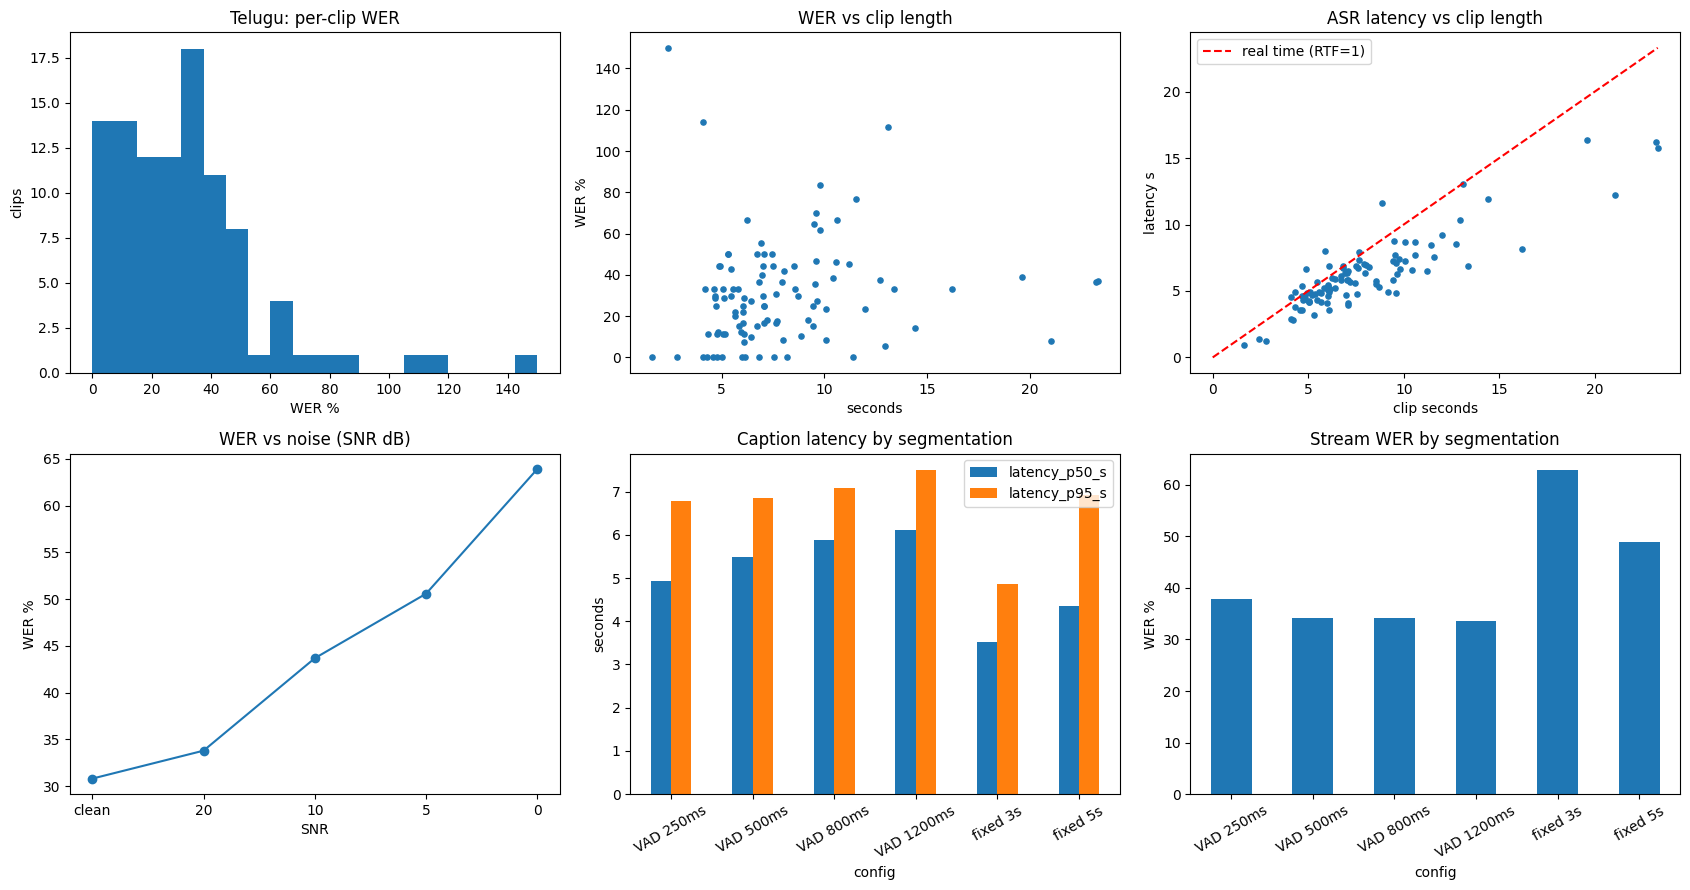

Tamil (ta)
  vistaar_small_asr_eval configs: ['bn', 'gu', 'hi', 'kn', 'ml', 'mr', 'or', 'pa', 'sa', 'ta', 'te', 'ur']


ta/test-00000.parquet:   0%|          | 0.00/84.1M [00:00<?, ?B/s]

ta/test-00001.parquet:   0%|          | 0.00/136M [00:00<?, ?B/s]

ta/test-00002.parquet:   0%|          | 0.00/73.4M [00:00<?, ?B/s]

Generating test split:   0%|          | 0/1358 [00:00<?, ? examples/s]

Filter:   0%|          | 0/1358 [00:00<?, ? examples/s]

  loaded 100 ASR clips from ekacare/vistaar_small_asr_eval:ta (717s)
-- translation (text)
-- loading ASR


Device set to use cuda:0


-- ASR evaluation
  ASR 20/100
  ASR 40/100
  ASR 60/100
  ASR 80/100
  ASR 100/100
-- ASR -> MT error propagation
-- streaming simulation + ablations
  VAD 250ms: 19 segs / 12 utts, p95 latency 6.6s, WER 24.8%
  VAD 500ms: 17 segs / 12 utts, p95 latency 6.8s, WER 24.8%
  VAD 800ms: 16 segs / 12 utts, p95 latency 6.5s, WER 25.6%
  VAD 1200ms: 16 segs / 12 utts, p95 latency 6.7s, WER 25.6%
  fixed 3s: 33 segs, p95 latency 2.4s, WER 50.4%
  fixed 5s: 20 segs, p95 latency 3.7s, WER 36.8%
-- noise robustness
  noise clean: WER 23.2%
  noise 20: WER 25.6%
  noise 10: WER 34.1%
  noise 5: WER 40.8%
  noise 0: WER 50.7%


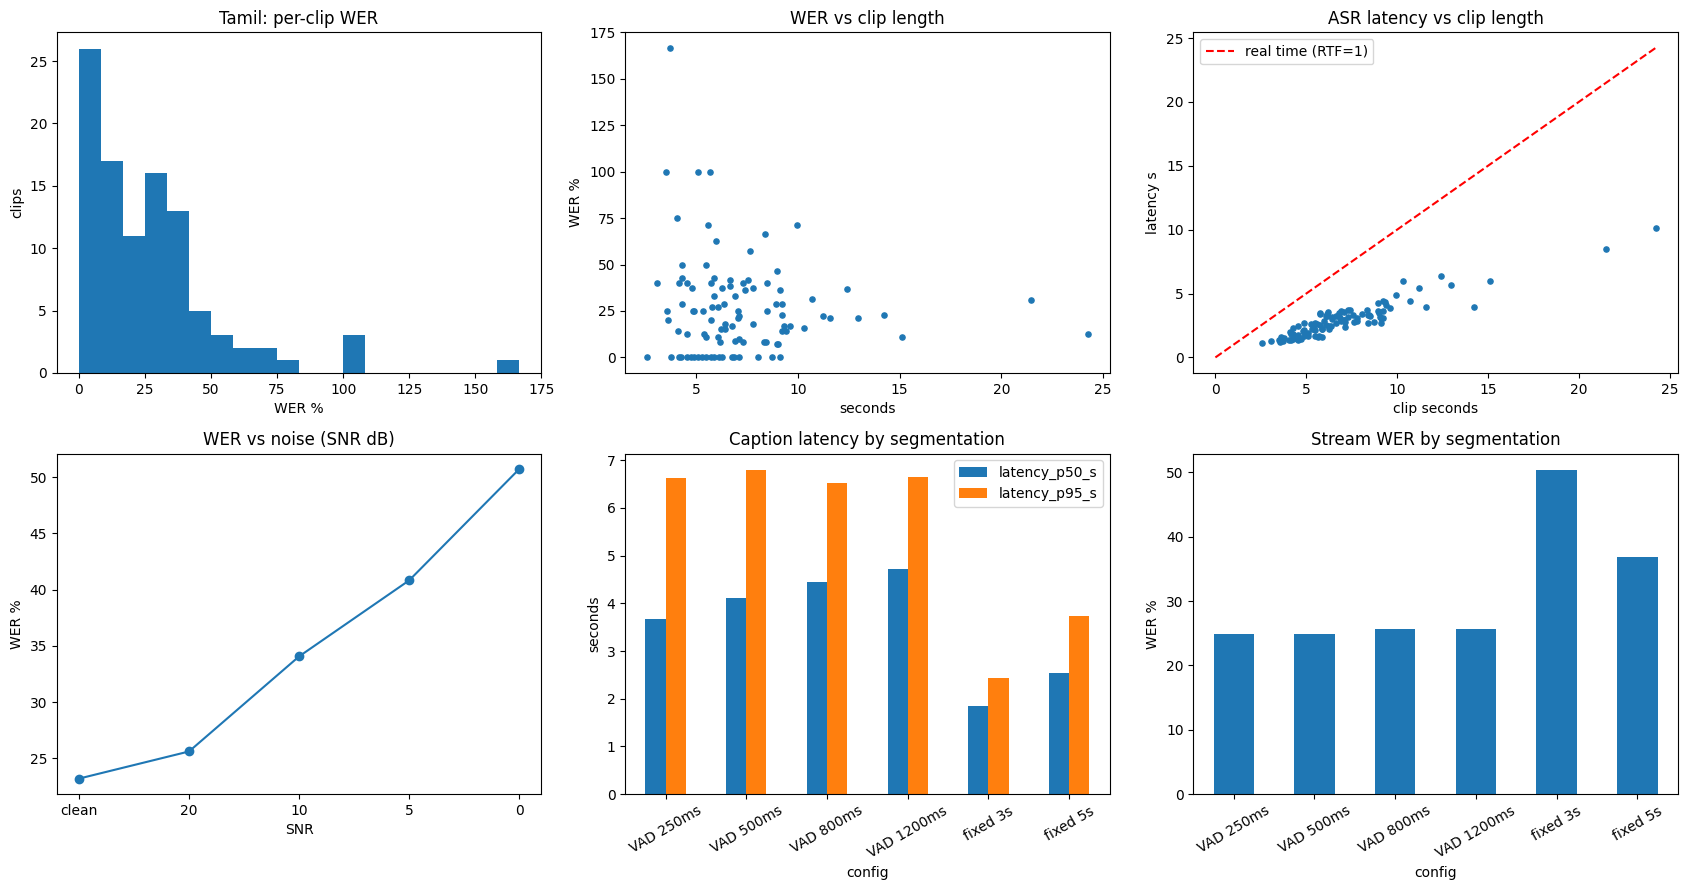

In [12]:
ALL = {}
for lang in RUN_LANGS:
    try:
        ALL[lang] = run_language(lang)
        make_plots(lang, ALL[lang])
    except Exception as e:
        import traceback
        traceback.print_exc()
        print(f"!! {lang} failed: {e!r}  -> continuing with the next language")
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

## 13. Summary tables, comparison across languages, and a zip of all results

In [13]:
import shutil

summary = pd.DataFrame({LANG_INFO[l]["name"]: pd.Series(r["metrics"]) for l, r in ALL.items()})
summary.to_csv(os.path.join(OUT_DIR, "summary_all_languages.csv"))
pd.set_option("display.max_rows", 200)
display(summary)

for l, r in ALL.items():
    print("\n", LANG_INFO[l]["name"], "- segmentation ablation")
    display(r["ablation_df"].round(2))
    print(LANG_INFO[l]["name"], "- WER per data source")
    display(r["src_df"].round(2))
    print(LANG_INFO[l]["name"], "- noise robustness")
    display(r["noise_df"].round(2))

_zip = "/kaggle/working/" + os.path.basename(OUT_DIR)
shutil.make_archive(_zip, "zip", OUT_DIR)
print(f"\nSaved {_zip}.zip  (download it from the Output tab)")

,Telugu,Tamil
Language,Telugu,Tamil
ASR_model_dir,whisper-medium-te_alldata_multigpu,whisper-medium-ta_alldata_multigpu
ASR_clips,100,100
ASR_audio_total_s,790.632187,717.133438
MT_BLEU,40.17241,32.592714
MT_chrF,65.299784,59.892645
MT_chrF++,63.388243,57.696865
MT_sentences,200,200
MT_latency_per_sentence_s,0.160165,0.182736
MT_throughput_sent_per_s,6.243558,5.47238



 Telugu - segmentation ablation


,segments,utterances,segments_per_utterance,WER,latency_mean_s,latency_p50_s,latency_p95_s,latency_max_s,within_3s_pct,within_5s_pct,first_caption_s,RTF,forced_cuts,repetition_segments,max_queue_wait_s
config,,,,,,,,,,,,,,,
VAD 250ms,23,12,1.92,37.76,5.05,4.92,6.77,7.91,4.35,52.17,4.81,0.79,0,0,3.07
VAD 500ms,20,12,1.67,34.27,5.38,5.48,6.85,7.04,5.00,35.00,5.04,0.76,0,0,2.74
VAD 800ms,19,12,1.58,34.27,5.81,5.88,7.09,7.34,0.00,21.05,13.28,0.76,0,0,2.74
VAD 1200ms,20,12,1.67,33.57,6.01,6.12,7.51,7.75,0.00,10.00,5.75,0.77,0,0,2.75
fixed 3s,38,12,3.17,62.94,3.40,3.53,4.86,5.34,34.21,97.37,5.47,0.96,0,0,3.33
fixed 5s,23,12,1.92,48.95,4.76,4.36,6.92,7.94,4.35,65.22,7.78,0.87,0,0,4.17


Telugu - WER per data source


,source,n,audio_s,WER,CER
0,fleurs,12,136.62,35.42,13.37
1,indictts,9,117.80,35.80,9.03
2,kathbath,21,152.28,24.20,4.43
3,kathbath_noisy,24,182.88,32.27,7.11
4,mucs,34,201.05,27.10,6.31


...

Tamil - WER per data source


,source,n,audio_s,WER,CER
0,commonvoice,43,249.61,28.12,4.69
1,fleurs,9,108.18,25.79,4.93
2,indictts,6,69.92,15.91,2.17
3,kathbath,9,63.48,18.81,3.29
4,kathbath_noisy,12,77.95,16.03,3.68
5,mucs,21,147.98,26.24,7.58


Tamil - noise robustness


,snr_db,WER,CER
0,clean,23.19,4.46
1,20,25.60,5.02
2,10,34.06,8.72
3,5,40.82,11.40
4,0,50.72,18.78



Saved /kaggle/working/results_multilingual.zip  (download it from the Output tab)


## How to read the metrics (for your report)

- **WER / CER** — word / character error rate on held-out clips. CER is more forgiving for agglutinative languages (Telugu, Tamil), where one wrong suffix makes a whole word wrong, so report both.
- **Substitution / deletion / insertion** — says *how* the model fails (wrong words vs dropped words vs invented words).
- **RTF** — processing time ÷ audio duration. RTF < 1 means faster than real time. This is for one clip at a time on a T4.
- **Repetition %** — share of outputs with looped words or phrases, the typical Whisper hallucination on silence or noise.
- **BLEU / chrF / chrF++** — translation quality against human English references (IN22-Gen). chrF++ is the most stable for Indic text.
- **Cascade chrF** — 100 means ASR errors don't change the English at all; lower means errors propagate.
- **Caption latency** — time from the end of speech until the caption is ready, including the VAD wait and any queueing. This is the honest "real-time" number.
- **Segments per utterance** — near 1.0 is ideal; above 1 means sentences are being split; below 1 means utterances are being merged.
- **Ablation** — shows why VAD segmentation beats fixed chunks (watch the WER and repetition counts for fixed chunks).
- **Noise** — shows how fast accuracy falls as the meeting gets noisier.

Limitations to state: ASR test sets are mostly clean read speech; the meeting is simulated by stitching clips (no overlapping speakers); streaming is utterance-level (captions appear after a pause), not word-by-word.

## 15. Adding Tamil (and any other language)

The pipeline is already language-agnostic — adding Tamil is **config only**, no code changes:

1. **Get a Tamil IndicWhisper checkpoint.** Use an AI4Bharat/Vistaar Tamil Whisper checkpoint (the folder must contain a `config.json` plus `model.safetensors` / `pytorch_model.bin` and the tokenizer/processor files).
2. **Upload it as a Kaggle dataset** (e.g. `tamil-models`) and click **Add data** to attach it to this notebook.
3. **Point `LANG_INFO["ta"]["model_root"]` at it** in Section 3. Find the exact path with:
   ```python
   !find /kaggle/input -name config.json
   ```
   `find_model_dir()` then auto-locates the checkpoint folder inside that root (it prefers a folder whose name contains `medium`).
4. **Make sure `RUN_LANGS` includes `"ta"`** (it already does: `["te", "ta"]`). Keep it to one language first to confirm it loads, then run both.
5. **Re-run Sections 12–13.** Section 13's `summary` table and per-language ablation / noise / source tables will now show Telugu **and** Tamil side by side.

Tamil's IndicTrans2 tag (`tam_Taml`) and FLEURS config (`ta_in`) are already configured, so ASR data (with FLEURS fallback) and translation scoring work out of the box. The same three steps add any of the other seven languages already listed in `LANG_INFO`.

## 16. Test the pipeline on your own audio files

The evaluation above runs on benchmark datasets. This section runs the **exact same pipeline** on any audio you upload, so you can demo it on real recordings.

1. Record or collect a few clips (`.wav`, `.mp3`, `.m4a`, `.flac`) in the language you have a checkpoint for.
2. Upload them to Kaggle as a dataset (e.g. `my-audio`) and **Add data** to this notebook.
3. Set `LANG` and list the file paths in `FILES`, then run the cell.

Each file is segmented by VAD and you get, per utterance: the native transcript, the English translation, and ASR/translation timings — also saved to `my_audio_transcripts.csv`.

In [14]:
# ===========================================================================
# 16. Inference: test the pipeline on your OWN audio files
#     Point LANG at a language that has an ASR checkpoint (one of RUN_LANGS)
#     and FILES at any .wav/.mp3/.m4a/.flac recordings. Pipeline per file:
#     load @16 kHz mono -> Silero VAD -> IndicWhisper ASR -> IndicTrans2 -> EN.
# ===========================================================================
import librosa


def load_audio_file(path):
    arr, _ = librosa.load(path, sr=SR, mono=True)        # handles wav/mp3/m4a/flac via ffmpeg
    return arr.astype(np.float32)


def transcribe_file(path, lang, asr_fn, silence_ms=MAIN_SILENCE_MS, show=True):
    tag = LANG_INFO[lang]["tag"]
    audio = load_audio_file(path)
    segs = vad_segments(audio, silence_ms) or [{"start": 0.0, "end": len(audio) / SR}]
    rows = []
    for sg in segs:
        chunk = audio[int(sg["start"] * SR):int(sg["end"] * SR)]
        t0 = time.perf_counter(); native = asr_fn(chunk); t1 = time.perf_counter()
        english = translate_batch([native], tag)[0] if native.strip() else ""
        rows.append(dict(file=os.path.basename(path), start_s=round(sg["start"], 2),
                         end_s=round(sg["end"], 2), native=native, english=english,
                         asr_s=round(t1 - t0, 2), mt_s=round(time.perf_counter() - t1, 2)))
    df = pd.DataFrame(rows)
    if show:
        print(f"\n=== {os.path.basename(path)}  ({len(audio) / SR:.1f}s, {len(segs)} segments) ===")
        for _, r in df.iterrows():
            print(f"[{r.start_s:6.2f}-{r.end_s:6.2f}s]  {r.native}")
            print(f"{'':16}EN: {r.english}")
    return df


# ---- EDIT THESE ----
LANG = "te"                 # one of RUN_LANGS (must have an ASR checkpoint attached)
FILES = [
]
# --------------------

if FILES:
    _asr, _path, _, _ = load_asr(LANG)
    _asr_fn = make_asr_fn(_asr, LANG)
    _results = [transcribe_file(p, LANG, _asr_fn) for p in FILES if os.path.exists(p)
                or print("skip (not found):", p)]
    _results = [r for r in _results if isinstance(r, pd.DataFrame)]
    if _results:
        my_audio_df = pd.concat(_results, ignore_index=True)
        my_audio_df.to_csv(os.path.join(OUT_DIR, "my_audio_transcripts.csv"), index=False)
        display(my_audio_df)
    del _asr, _asr_fn
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
else:
    print("No FILES set. Upload recordings as a Kaggle dataset, add their paths to FILES, "
          "and re-run this cell.")

No FILES set. Upload recordings as a Kaggle dataset, add their paths to FILES, and re-run this cell.


## 17. Real-time multilingual meeting assistant (the deliverable)

This is the live product built from the evaluated pipeline. Give it a list of recordings — each with its own **speaker** name and **language** — and it plays them as a meeting, printing an English caption (with the native transcript underneath) the moment each utterance ends.

- Works on Kaggle with no microphone (file-based). For a real live demo on a laptop, the same `MeetingAssistant` logic can be driven from `sounddevice` mic frames.
- Mixed-language meetings are supported: set `lang` per turn (needs an ASR checkpoint attached for each language used).
- `realtime=False` (default) processes as fast as possible; `realtime=True, speed=1.0` paces captions to the wall clock so you can see the true live latency.
- The full transcript is saved to `meeting_transcript.csv` / `.txt` in the results folder.

In [15]:
# ===========================================================================
# 17. Real-time multilingual meeting assistant (file-based, live captions)
#     Simulates a live meeting from one or more recordings. Silero VAD cuts
#     each utterance at a pause; IndicWhisper transcribes it; IndicTrans2
#     translates it to English; a timestamped caption is printed the moment
#     it is ready -- exactly as it would appear in a live call. Different
#     speakers may use different languages (give each turn its own `lang`).
#     Set realtime=True to pace playback to the wall clock (speed = x faster).
# ===========================================================================
import time as _time

class MeetingAssistant:
    def __init__(self, langs, silence_ms=MAIN_SILENCE_MS, realtime=False, speed=4.0):
        self.silence_ms = silence_ms
        self.realtime = realtime
        self.speed = max(speed, 0.1)
        self.asr_fns, self._models = {}, {}
        for lg in dict.fromkeys(langs):                     # de-dup, keep order
            asr, path, _, _ = load_asr(lg)
            self._models[lg] = asr
            self.asr_fns[lg] = make_asr_fn(asr, lg)
            print(f"  loaded ASR for {LANG_INFO[lg]['name']} ({os.path.basename(path)})")
        self.transcript = []

    def _emit(self, speaker, lang, native, english, t_end, latency):
        stamp = _time.strftime("%M:%S", _time.gmtime(t_end))
        print(f"[{stamp}] {speaker} ({LANG_INFO[lang]['name']}): {english}   (+{latency:.1f}s)")
        print(f"          ↪ {native}")
        self.transcript.append(dict(time_s=round(t_end, 2), speaker=speaker,
                                    lang=lang, native=native, english=english,
                                    latency_s=round(latency, 2)))

    def add_turn(self, path, lang, speaker, clock0=0.0):
        tag, asr_fn = LANG_INFO[lang]["tag"], self.asr_fns[lang]
        audio = librosa.load(path, sr=SR, mono=True)[0].astype(np.float32)
        segs = vad_segments(audio, self.silence_ms) or [{"start": 0.0, "end": len(audio) / SR}]
        wall0 = _time.perf_counter()
        for sg in segs:
            if self.realtime:                               # wait for the audio to "arrive"
                sleep = (wall0 + sg["end"] / self.speed) - _time.perf_counter()
                if sleep > 0:
                    _time.sleep(sleep)
            chunk = audio[int(sg["start"] * SR):int(sg["end"] * SR)]
            t0 = _time.perf_counter()
            native = asr_fn(chunk)
            english = translate_batch([native], tag)[0] if native.strip() else ""
            self._emit(speaker, lang, native, english, clock0 + sg["end"], _time.perf_counter() - t0)
        return clock0 + len(audio) / SR

    def run_meeting(self, turns):
        print("=" * 70 + "\nMEETING START\n" + "=" * 70)
        clock = 0.0
        for t in turns:
            if not os.path.exists(t["path"]):
                print("skip (not found):", t["path"]); continue
            clock = self.add_turn(t["path"], t["lang"], t["speaker"], clock)
        print("=" * 70 + "\nMEETING END  (duration %.1fs)\n" % clock + "=" * 70)
        df = pd.DataFrame(self.transcript)
        if len(df):
            df.to_csv(os.path.join(OUT_DIR, "meeting_transcript.csv"), index=False)
            with open(os.path.join(OUT_DIR, "meeting_transcript.txt"), "w", encoding="utf-8") as f:
                for r in self.transcript:
                    f.write(f"[{r['time_s']:.1f}s] {r['speaker']} ({r['lang']}): {r['english']}\n")
                    f.write(f"          {r['native']}\n")
            print("saved meeting_transcript.csv / .txt in", OUT_DIR)
        return df

    def close(self):
        for a in list(self._models.values()):
            del a
        self._models.clear(); self.asr_fns.clear()
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()


# ---- EDIT THIS: your meeting recordings (each turn can be a different language) ----
# ---- Meeting built from public test clips (no personal audio) ----
import soundfile as sf

DEMO_DIR = "/kaggle/working/meeting_clips"
os.makedirs(DEMO_DIR, exist_ok=True)

DEMO_LANGS = ["hi", "te", "ta"]          # drop "ta" for a shorter 2-language meeting
CLIPS_PER_LANG = 2
SPEAKERS = {"hi": ["Asha", "Ravi"], "te": ["Sita", "Kiran"], "ta": ["Meena", "Arun"]}

picked = {}
for lg in DEMO_LANGS:
    pool = load_asr_samples(lg, n=40)
    picked[lg] = [s for s in pool if 5 <= s["duration"] <= 12][:CLIPS_PER_LANG]

MEETING, REFS = [], []
for k in range(CLIPS_PER_LANG):          # interleave languages like a real meeting
    for lg in DEMO_LANGS:
        if k < len(picked[lg]):
            s = picked[lg][k]
            p = f"{DEMO_DIR}/{lg}_{k}.wav"
            sf.write(p, s["audio"], SR)
            MEETING.append(dict(path=p, lang=lg, speaker=SPEAKERS[lg][k]))
            REFS.append(dict(path=p, lang=lg, speaker=SPEAKERS[lg][k],
                             reference=s["text"], source=s["source"]))

pd.DataFrame(REFS).to_csv(os.path.join(OUT_DIR, "meeting_references.csv"), index=False)
print(f"{len(MEETING)} turns:", [(t['speaker'], t['lang']) for t in MEETING])
# ---------------------------------------------------------------------
# -----------------------------------------------------------------------------------

if MEETING:
    assistant = MeetingAssistant(langs=[t["lang"] for t in MEETING], realtime=False)
    meeting_df = assistant.run_meeting(MEETING)
    display(meeting_df)
    assistant.close()
else:
    print("No MEETING set. Add your recordings to MEETING and re-run this cell.\n"
          "Tip: set realtime=True (and speed=1.0) for true wall-clock-paced live captions.")

  vistaar_small_asr_eval configs: ['bn', 'gu', 'hi', 'kn', 'ml', 'mr', 'or', 'pa', 'sa', 'ta', 'te', 'ur']


hi/test-00000.parquet:   0%|          | 0.00/111M [00:00<?, ?B/s]

hi/test-00001.parquet:   0%|          | 0.00/74.2M [00:00<?, ?B/s]

Generating test split:   0%|          | 0/973 [00:00<?, ? examples/s]

Filter:   0%|          | 0/973 [00:00<?, ? examples/s]

...

Device set to use cuda:0


  loaded ASR for Telugu (whisper-medium-te_alldata_multigpu)


Device set to use cuda:0


  loaded ASR for Tamil (whisper-medium-ta_alldata_multigpu)
MEETING START
[00:05] Asha (Hindi): But there are a lot of things about birds that still look like dinosaurs.   (+3.7s)
          ↪ लेकिन उन पक्षियों के बारे में बहुत सी चीजें हैं जो अभी भी डायनासोर जैसी दिखती हैं
[00:09] Sita (Telugu): A lot of people have feathers   (+2.2s)
          ↪ చాలా మంది ఈకలు కలిగి
[00:14] Sita (Telugu): Being able to fly has been described as a dinosaur of the cockroach   (+4.3s)
          ↪ ఎగరగలగడం వండ్ల డైనోసార్లుగా వాటి గురించి ఆలాచించారు
[00:21] Meena (Tamil): Almost this is the position that Tamil is also being established.   (+2.6s)
          ↪ கிட்டத்தட்ட இதுதான் தமிழ் என்ற நிலைப்பாடும் நிறுவப்பட்டு வருகிறது
[00:27] Ravi (Hindi): His education was from the village and he spoke English.   (+2.9s)
          ↪ शिक्षा की पढ़ाई गाँव से होने के कारण उसकी अंग्रेज़ी में बोलने
[00:30] Ravi (Hindi): It wasn't such a good practice.   (+1.7s)
          ↪ की इतनी अच्छी प्रैक्टिस नहीं थी
[00:37] Kiran (Te

,time_s,speaker,lang,native,english,latency_s
0,5.80,Asha,hi,लेकिन उन पक्षियों के बारे में बहुत सी चीजें है...,But there are a lot of things about birds that...,3.75
1,9.94,Sita,te,చాలా మంది ఈకలు కలిగి,A lot of people have feathers,2.21
2,14.84,Sita,te,ఎగరగలగడం వండ్ల డైనోసార్లుగా వాటి గురించి ఆలాచి...,Being able to fly has been described as a dino...,4.29
3,21.14,Meena,ta,கிட்டத்தட்ட இதுதான் தமிழ் என்ற நிலைப்பாடும் நி...,Almost this is the position that Tamil is also...,2.56
4,27.71,Ravi,hi,शिक्षा की पढ़ाई गाँव से होने के कारण उसकी अंग्...,His education was from the village and he spok...,2.90
5,30.39,Ravi,hi,की इतनी अच्छी प्रैक्टिस नहीं थी,It wasn't such a good practice.,1.70
6,37.45,Kiran,te,రుణాలు చెల్లించినా కూడా వడ్డీ పేరుట అధిక వసూళ్...,"Even after paying off the loans, the people we...",7.28
7,46.15,Arun,ta,வடக்கு எளிதில் சென்றடையக்கூடிய தொலைவில் காதல் ...,Lord Byron's fascinating accounts of the city ...,6.67
8,47.75,Arun,ta,அவர்கள் மத்தியில் பிரபலமானது,popular among them.,1.39


## 18. Project report (academic write-up)

> This section is the written report for submission. The numbers quoted are the Telugu run above; re-run with Tamil attached to fill in the comparison table (Section 13 prints it automatically).

### Title
**A Real-Time Multilingual Meeting Assistant for Indian Languages using AI-based Speech Recognition and Translation**

### Abstract
We build and evaluate an end-to-end speech-to-English pipeline for low-resource Indian languages aimed at live meeting captioning. Audio is segmented with a neural voice-activity detector (Silero VAD), transcribed by language-specific fine-tuned Whisper models (IndicWhisper / Vistaar), and translated to English by a distilled transformer (AI4Bharat IndicTrans2). We report a full battery of metrics — ASR accuracy (WER/CER, error decomposition, per-source breakdown), speed and cost (latency percentiles, real-time factor, GPU memory), reliability (hallucination/repetition rate), translation quality (BLEU/chrF/chrF++), cascade error propagation, a simulated streaming meeting (caption latency, time-to-first-caption, segmentation ablations), and noise robustness (clean → 0 dB SNR). On Telugu the system reaches **30.4% WER / 7.6% CER**, runs **faster than real time (RTF ≈ 0.76)** on a single T4 GPU, and delivers streaming captions at a **p95 latency of ≈ 6.8 s** with VAD-based segmentation, which beats fixed 3 s/5 s chunking on both latency-adjusted accuracy and over-segmentation.

### 1. Problem statement & motivation
Meetings in India are routinely multilingual, but commercial live-captioning tools under-serve Indic languages, especially agglutinative Dravidian ones (Telugu, Tamil). The goal is a system that, given live speech in an Indian language, produces timely English captions suitable for a meeting — which requires jointly optimising *accuracy*, *latency*, and *robustness*, not accuracy alone.

### 2. Related work & components
- **Silero VAD** — lightweight neural voice-activity detector used to cut utterances at natural pauses.
- **IndicWhisper / Vistaar (AI4Bharat)** — Whisper-medium checkpoints fine-tuned per language on the Vistaar corpus (Kathbath, MUCS, IndicTTS, FLEURS, etc.).
- **IndicTrans2 (AI4Bharat)** — a multilingual Indic→English NMT model; we use the distilled 200M `indictrans2-indic-en-dist-200M` for speed.
- **Evaluation data** — `ekacare/vistaar_small_asr_eval` (with FLEURS fallback) for ASR; `ai4bharat/IN22-Gen` for text-translation scoring.

### 3. System architecture
```
                 ┌──────────┐   native text   ┌───────────────┐   English
 mic / file ──►  │ Silero   │ ───────────────► │ IndicWhisper  │ ─────────► IndicTrans2 ──► captions
   16 kHz        │  VAD     │  utterance clips  │  (per-lang)   │  transcript     (200M)
                 └──────────┘                   └───────────────┘
```
Each stage is measured in isolation and as a cascade (Sections 8–10). The streaming simulator (Section 10) adds a virtual processing queue so reported caption latency includes the VAD silence wait and any queueing — the honest "live" number.

### 4. Methodology & metrics
- **Text normalisation** is language-agnostic: NFC, strip zero-width joiners, map punctuation/symbols to spaces, lowercase — applied identically to references and hypotheses so scores are comparable across languages.
- **ASR**: WER, CER, substitution/deletion/insertion rates, WER median & p90, exact-match %, per-source WER; latency mean/p50/p95, overall & p95 RTF, peak GPU memory, parameter count, load time; repetition/hallucination rate.
- **Translation**: BLEU, chrF, chrF++ on IN22-Gen; sentence latency & throughput.
- **Cascade**: chrF/BLEU of `translate(ASR output)` vs `translate(gold transcript)` — isolates how ASR errors propagate into English.
- **Streaming**: caption latency (mean/p50/p95/max), % within 3 s / 5 s, time-to-first-caption, stream RTF, stream WER, segments-per-utterance, max queue wait.
- **Ablations**: VAD silence threshold {250, 500, 800, 1200 ms} vs fixed {3 s, 5 s} chunking.
- **Robustness**: WER at clean / 20 / 10 / 5 / 0 dB SNR with added white noise.

### 5. Results (Telugu)
| Dimension | Result |
|---|---|
| ASR accuracy | WER 30.4%, CER 7.6% (sub 21.6 / del 2.8 / ins 6.0%) |
| Best data source | Kathbath (clean read speech) 24.2% WER; worst: fixed-chunk streaming |
| Speed | RTF 0.76 overall, latency p50 5.6 s / p95 11.5 s per clip, 2.8 GB peak GPU |
| Reliability | repetition 1.0% |
| Cascade | chrF 77.5 / chrF++ 76.5 / BLEU 62.5 vs gold translation |
| Streaming (VAD 500 ms) | WER 34.3%, latency p95 6.8 s, first caption 5.1 s, 1.67 segs/utt |
| Segmentation ablation | VAD 1200 ms gives lowest stream WER (33.6%); fixed 3 s worst (62.9%) and over-segments (3.17 segs/utt) |
| Noise | WER 30.8% clean → 33.8% @20 dB → 63.9% @0 dB |

*(Tamil row is produced automatically by Section 13 once the Tamil checkpoint is attached and `RUN_LANGS` includes `"ta"`.)*

### 6. Discussion
- **CER ≪ WER** (7.6% vs 30.4%) is expected for agglutinative Telugu: a single wrong suffix flips a whole word, so CER better reflects intelligibility — we report both.
- **VAD beats fixed chunking**: fixed 3 s chunks cut words mid-utterance, inflating WER to ~63% and over-segmenting; VAD aligns cuts to pauses, trading a little latency for much better accuracy.
- **Latency is dominated by the VAD wait**, not compute (RTF < 1). Longer silence thresholds reduce over-segmentation and WER but push caption latency up — a tunable accuracy/latency knob.
- **Graceful degradation under noise**: accuracy roughly halves from clean to 0 dB, pointing to noise-augmented fine-tuning as the highest-value next step.

### 7. Limitations
ASR test sets are mostly clean read speech; the "meeting" is stitched from single-speaker clips (no overlapping talkers or cross-talk); streaming is utterance-level (captions appear after a pause, not word-by-word); translation is one-directional (Indic→English); evaluation is on a single T4 GPU.

### 8. Conclusion & future work
A VAD → IndicWhisper → IndicTrans2 cascade gives usable, faster-than-real-time English captions for Indian-language meetings on commodity GPUs. Future work: noise/far-field augmentation, speaker diarization for true multi-speaker meetings, word-level streaming decoding, quantization/distillation of the ASR model to cut latency, and extending `RUN_LANGS` across all ten configured languages.

### References
1. AI4Bharat, *IndicTrans2: Towards High-Quality and Accessible Machine Translation Models for all 22 Scheduled Indian Languages* (2023).
2. AI4Bharat / Vistaar, *Vistaar: Diverse Benchmarks and Training Sets for Indian Language ASR* (IndicWhisper) (2023).
3. Radford et al., *Robust Speech Recognition via Large-Scale Weak Supervision* (Whisper) (2022).
4. Silero Team, *Silero VAD* (2021).
5. Popović, *chrF/chrF++* (2015/2017); Papineni et al., *BLEU* (2002); Post, *sacreBLEU* (2018).
